# 2C. CNN - Sign Language MNIST
CNN baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("../datasets/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
x_train = train.drop(columns="label").to_numpy().reshape(-1, 28, 28, 1)
x_test = test.drop(columns="label").to_numpy().reshape(-1, 28, 28, 1)

print(x_train.shape, x_test.shape)

(27455, 28, 28, 1) (7172, 28, 28, 1)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(25, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,905 (480.10 KB)

 Trainable params: 122,905 (480.10 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=5)

Epoch 1/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7251 - loss: 0.9349 - val_accuracy: 0.8153 - val_loss: 0.5495
Epoch 2/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9889 - loss: 0.0633 - val_accuracy: 0.8731 - val_loss: 0.4329
Epoch 3/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9977 - loss: 0.0156 - val_accuracy: 0.9038 - val_loss: 0.3412
Epoch 4/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9997 - loss: 0.0034 - val_accuracy: 0.9136 - val_loss: 0.3578
Epoch 5/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9950 - loss: 0.0168 - val_accuracy: 0.8438 - val_loss: 0.5894


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test loss: {loss:.4f}  test accuracy: {acc:.4f}")

  1/225 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9062 - loss: 0.3210

 45/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8458 - loss: 0.6060

 87/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8481 - loss: 0.5879

120/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8474 - loss: 0.5806

152/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8481 - loss: 0.5756

188/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8446 - loss: 0.5846

223/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8438 - loss: 0.5905

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8438 - loss: 0.5894


test loss: 0.5894  test accuracy: 0.8438


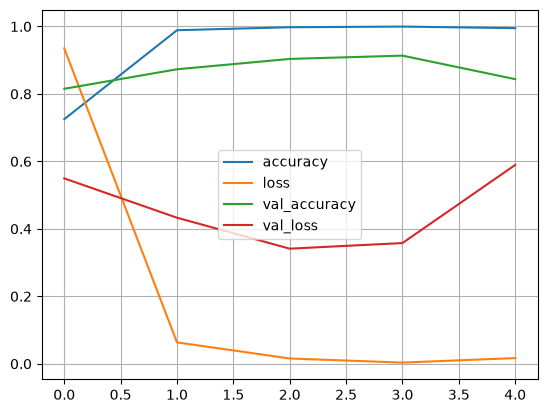

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()